In [1]:
# Installation et Configuration
!pip install -q kaggle opencv-python-headless scikit-learn torch torchvision timm transformers tqdm seaborn

import copy
import json
import os
import cv2
import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
import seaborn as sns
from sklearn.metrics import (
    ConfusionMatrixDisplay,
    accuracy_score,
    auc,
    confusion_matrix,
    f1_score,
    precision_score,
    recall_score,
    roc_auc_score,
    roc_curve,
)
from sklearn.model_selection import train_test_split
from sklearn.utils.class_weight import compute_class_weight
import timm
import torch
import torch.nn as nn
import torch.optim as optim
from torch.utils.data import DataLoader, Dataset
from torchvision import transforms
from tqdm import tqdm

SEED = 42
np.random.seed(SEED)
torch.manual_seed(SEED)
if torch.cuda.is_available():
  torch.cuda.manual_seed_all(SEED)

DEVICE = torch.device("cuda" if torch.cuda.is_available() else "cpu")
print(f"Utilisation du matériel : {DEVICE}")

IMG_SIZE = 224

Utilisation du matériel : cuda


In [2]:
# Téléchargement du Dataset
import kagglehub

# Téléchargement automatique du dataset bharathry/glaucoma-dataset-for-ai-diagnosis
DATA_DIR = kagglehub.dataset_download(
    "bharathry/glaucoma-dataset-for-ai-diagnosis"
)
print("\nChemin du dataset téléchargé :", DATA_DIR)

# Inspection de l'arborescence
print("\nArborescence des fichiers :")
for root, dirs, fnames in os.walk(DATA_DIR):
  n_images = sum(
      1
      for f in fnames
      if f.lower().endswith((".png", ".jpg", ".jpeg", ".tif", ".tiff"))
  )
  if n_images > 0:
    print(f" -> {root} : {n_images} images")

100%|██████████| 2.67G/2.67G [02:16<00:00, 21.0MB/s]

Extracting files...



Chemin du dataset téléchargé : /root/.cache/kagglehub/datasets/bharathry/glaucoma-dataset-for-ai-diagnosis/versions/1

Arborescence des fichiers :
 -> /root/.cache/kagglehub/datasets/bharathry/glaucoma-dataset-for-ai-diagnosis/versions/1/Glaucoma Dataset for AI Diagnosis/test/glaucoma/Images : 400 images
 -> /root/.cache/kagglehub/datasets/bharathry/glaucoma-dataset-for-ai-diagnosis/versions/1/Glaucoma Dataset for AI Diagnosis/train/normal/Glaucoma_Negative : 386 images
 -> /root/.cache/kagglehub/datasets/bharathry/glaucoma-dataset-for-ai-diagnosis/versions/1/Glaucoma Dataset for AI Diagnosis/train/glaucoma/Images - ORIGA : 650 images
 -> /root/.cache/kagglehub/datasets/bharathry/glaucoma-dataset-for-ai-diagnosis/versions/1/Glaucoma Dataset for AI Diagnosis/train/glaucoma/Images - REFUGE : 400 images
 -> /root/.cache/kagglehub/datasets/bharathry/glaucoma-dataset-for-ai-diagnosis/versions/1/Glaucoma Dataset for AI Diagnosis/train/glaucoma/Glaucoma_Positive : 134 images
 -> /root/.cache

In [3]:
# Chargement et Split du Dataset
def build_dataframe(data_dir):
  records = []
  for root, dirs, fnames in os.walk(data_dir):
    folder_path = root.lower()

    for f in fnames:
      if f.lower().endswith((".png", ".jpg", ".jpeg", ".tif", ".tiff")):
        img_path = os.path.join(root, f)

        # Détection de la classe via le chemin d'accès complet du dossier
        if "non_glaucoma" in folder_path or "normal" in folder_path:
          label = 0  # Sain
        elif "glaucoma" in folder_path:
          label = 1  # Glaucome
        else:
          continue

        records.append({"path": img_path, "label": label})

  df = pd.DataFrame(records)

  # Sécurité si l'arborescence utilise d'autres noms de dossiers
  if df.empty or df["label"].nunique() < 2:
    print(
        "Avertissement : Filtrage par dossier strict échoué. Tentative de"
        " détection élargie..."
    )
    records = []
    for root, dirs, fnames in os.walk(data_dir):
      for f in fnames:
        if f.lower().endswith((".png", ".jpg", ".jpeg", ".tif", ".tiff")):
          full_path = os.path.join(root, f).lower()
          if "glaucom" in full_path and "non" not in full_path:
            label = 1
          else:
            label = 0
          records.append({"path": os.path.join(root, f), "label": label})
    df = pd.DataFrame(records)

  return df


df = build_dataframe(DATA_DIR)

# Split train / val / test
train_df, temp_df = train_test_split(
    df, test_size=0.3, stratify=df["label"], random_state=SEED
)
val_df, test_df = train_test_split(
    temp_df, test_size=0.5, stratify=temp_df["label"], random_state=SEED
)

print(f"Total dataset: {len(df)} images")
print(
    "Distribution globale :\n"
    f"{df['label'].value_counts().rename({0: 'Sain (0)', 1: 'Glaucome (1)'})}\n"
)
print(f"Train: {len(train_df)} | Val: {len(val_df)} | Test: {len(test_df)}")

Total dataset: 3160 images
Distribution globale :
label
Glaucome (1)    2678
Sain (0)         482
Name: count, dtype: int64

Train: 2212 | Val: 474 | Test: 474


In [4]:
# Data Loaders PyTorch
def load_raw(path):
  img = cv2.imread(path)
  img = cv2.cvtColor(img, cv2.COLOR_BGR2RGB)
  img = cv2.resize(img, (IMG_SIZE, IMG_SIZE))
  return img


def load_preprocessed(path):
  img = cv2.imread(path)
  img = cv2.cvtColor(img, cv2.COLOR_BGR2RGB)

  lab = cv2.cvtColor(img, cv2.COLOR_RGB2LAB)
  l, a, b = cv2.split(lab)
  clahe = cv2.createCLAHE(clipLimit=2.0, tileGridSize=(8, 8))
  l_eq = clahe.apply(l)
  img_eq = cv2.cvtColor(cv2.merge((l_eq, a, b)), cv2.COLOR_LAB2RGB)

  h, w, _ = img_eq.shape
  crop_ratio = 0.9
  ch, cw = int(h * crop_ratio), int(w * crop_ratio)
  y0, x0 = (h - ch) // 2, (w - cw) // 2
  img_eq = img_eq[y0 : y0 + ch, x0 : x0 + cw]

  img_eq = cv2.resize(img_eq, (IMG_SIZE, IMG_SIZE))
  return img_eq


class FundusDataset(Dataset):

  def __init__(self, df, loader_fn, transform=None):
    self.df = df.reset_index(drop=True)
    self.loader_fn = loader_fn
    self.transform = transform

  def __len__(self):
    return len(self.df)

  def __getitem__(self, idx):
    row = self.df.iloc[idx]
    img = self.loader_fn(row["path"])
    label = row["label"]

    if self.transform:
      img = self.transform(img)

    return img, torch.tensor(label, dtype=torch.float32)


transform_pipeline = transforms.Compose([
    transforms.ToPILImage(),
    transforms.Resize((IMG_SIZE, IMG_SIZE)),
    transforms.ToTensor(),
    transforms.Normalize(mean=[0.485, 0.456, 0.406], std=[0.229, 0.224, 0.225]),
])

train_loader_raw = DataLoader(
    FundusDataset(train_df, load_raw, transform_pipeline),
    batch_size=32,
    shuffle=True,
)
val_loader_raw = DataLoader(
    FundusDataset(val_df, load_raw, transform_pipeline),
    batch_size=32,
    shuffle=False,
)
test_loader_raw = DataLoader(
    FundusDataset(test_df, load_raw, transform_pipeline),
    batch_size=32,
    shuffle=False,
)

train_loader_prep = DataLoader(
    FundusDataset(train_df, load_preprocessed, transform_pipeline),
    batch_size=32,
    shuffle=True,
)
val_loader_prep = DataLoader(
    FundusDataset(val_df, load_preprocessed, transform_pipeline),
    batch_size=32,
    shuffle=False,
)
test_loader_prep = DataLoader(
    FundusDataset(test_df, load_preprocessed, transform_pipeline),
    batch_size=32,
    shuffle=False,
)

In [5]:
# Définition du Modèle RETFound
def build_retfound_model():
  model = timm.create_model(
      "vit_base_patch16_224", pretrained=True, num_classes=1
  )

  for param in model.parameters():
    param.requires_grad = False

  for param in model.head.parameters():
    param.requires_grad = True
  for param in model.blocks[-1].parameters():
    param.requires_grad = True

  return model.to(DEVICE)


# Calcul direct et sécurisé du pos_weight (Ratio Negatifs / Positifs)
num_neg = (train_df["label"] == 0).sum()
num_pos = (train_df["label"] == 1).sum()

print(
    f"Échantillons Sain (0) : {num_neg} | Échantillons Glaucome (1) :"
    f" {num_pos}"
)

if num_pos == 0 or num_neg == 0:
  raise ValueError(
      "Une seule classe a été détectée dans train_df. Vérifiez la structure"
      " du dataset dans la Cellule 3."
  )

pos_weight = torch.tensor([num_neg / num_pos]).to(DEVICE)
print("Poids relatif pour la perte binaire (pos_weight) :", pos_weight.item())

Échantillons Sain (0) : 337 | Échantillons Glaucome (1) : 1875
Poids relatif pour la perte binaire (pos_weight) : 0.17973333333333333


In [6]:
# Entrainement du modele
def train_retfound(
    train_loader,
    val_loader,
    epochs=15,
    lr=1e-4,
    pos_weight=None,
    checkpoint_path="retfound_checkpoint.pth",
    resume=True
):
    # CRÉATION DU MODÈLE
    model = build_retfound_model().to(DEVICE)

    #  LOSS
    loss_kwargs = {}
    if pos_weight is not None:
        loss_kwargs["pos_weight"] = pos_weight.to(DEVICE)

    criterion = nn.BCEWithLogitsLoss(**loss_kwargs)

    # OPTIMIZER
    optimizer = optim.AdamW(
        filter(lambda p: p.requires_grad, model.parameters()),
        lr=lr,
        weight_decay=1e-2,
    )

    # VARIABLES DE REPRISE
    start_epoch = 0
    best_val_auc = 0.0
    best_model_weights = None

    history = {
        "train_loss": [],
        "train_acc": [],
        "val_loss": [],
        "val_acc": [],
        "val_auc": [],
    }

    # CHARGER LE CHECKPOINT S'IL EXISTE
    if resume and os.path.exists(checkpoint_path):

        print(f"\nCheckpoint trouvé : {checkpoint_path}")
        print("Reprise de l'entraînement...")

        checkpoint = torch.load(
            checkpoint_path,
            map_location=DEVICE
        )

        model.load_state_dict(checkpoint["model_state_dict"])
        optimizer.load_state_dict(checkpoint["optimizer_state_dict"])

        start_epoch = checkpoint["epoch"] + 1
        best_val_auc = checkpoint["best_val_auc"]
        history = checkpoint["history"]

        print(f"Reprise à partir de l'époque {start_epoch + 1}")
        print(f"Meilleur Val AUC précédent : {best_val_auc:.4f}")

    else:
        print("\nNouvel entraînement.")

    # BOUCLE D'ENTRAÎNEMENT
    for epoch in range(start_epoch, epochs):

        # ENTRAÎNEMENT
        model.train()

        running_loss = 0.0
        train_preds = []
        train_targets = []

        for imgs, labels in train_loader:

            imgs = imgs.to(DEVICE)
            labels = labels.to(DEVICE).float()

            optimizer.zero_grad()

            outputs = model(imgs).view(-1)

            loss = criterion(outputs, labels)

            loss.backward()
            optimizer.step()

            running_loss += loss.item() * imgs.size(0)

            probs = torch.sigmoid(outputs)

            train_preds.extend(
                probs.detach().cpu().numpy()
            )

            train_targets.extend(
                labels.cpu().numpy()
            )

        epoch_loss = (
            running_loss /
            len(train_loader.dataset)
        )

        epoch_acc = accuracy_score(
            train_targets,
            (np.array(train_preds) >= 0.5).astype(int)
        )

        # VALIDATION
        model.eval()

        val_loss = 0.0
        val_preds = []
        val_targets = []

        with torch.no_grad():

            for imgs, labels in val_loader:

                imgs = imgs.to(DEVICE)
                labels = labels.to(DEVICE).float()

                outputs = model(imgs).view(-1)

                loss = criterion(outputs, labels)

                val_loss += (
                    loss.item() *
                    imgs.size(0)
                )

                probs = torch.sigmoid(outputs)

                val_preds.extend(
                    probs.cpu().numpy()
                )

                val_targets.extend(
                    labels.cpu().numpy()
                )

        val_epoch_loss = (
            val_loss /
            len(val_loader.dataset)
        )

        val_acc = accuracy_score(
            val_targets,
            (np.array(val_preds) >= 0.5).astype(int)
        )

        try:
            val_auc = roc_auc_score(
                val_targets,
                val_preds
            )
        except ValueError:
            val_auc = 0.0

        # HISTORIQUE
        history["train_loss"].append(epoch_loss)
        history["train_acc"].append(epoch_acc)

        history["val_loss"].append(val_epoch_loss)
        history["val_acc"].append(val_acc)
        history["val_auc"].append(val_auc)

        # AFFICHAGE
        print(
            f"Epoch {epoch+1}/{epochs} - "
            f"Loss: {epoch_loss:.4f} | "
            f"Train Acc: {epoch_acc*100:.2f}% | "
            f"Val Loss: {val_epoch_loss:.4f} | "
            f"Val Acc: {val_acc*100:.2f}% | "
            f"Val AUC: {val_auc:.4f}"
        )

        # MEILLEUR MODÈLE
        if val_auc > best_val_auc:

            best_val_auc = val_auc

            best_model_weights = copy.deepcopy(
                model.state_dict()
            )

        # SAUVEGARDE DU CHECKPOINT
        torch.save({

            "epoch": epoch,

            "model_state_dict":
                model.state_dict(),

            "optimizer_state_dict":
                optimizer.state_dict(),

            "best_val_auc":
                best_val_auc,

            "history":
                history,

        }, checkpoint_path)

        print(
            f"Checkpoint sauvegardé : "
            f"{checkpoint_path}"
        )

    # RECHARGER LE MEILLEUR MODÈLE
    if best_model_weights is not None:
        model.load_state_dict(best_model_weights)

    return model, history

In [7]:
print("\n=== Entraînement RETFound SANS prétraitement ===")

retfound_raw, hist_rf_raw = train_retfound(
    train_loader_raw,
    val_loader_raw,
    epochs=15,
    pos_weight=pos_weight,
    checkpoint_path="retfound_raw_checkpoint.pth"
)

print("\n=== Entraînement RETFound AVEC prétraitement ===")

retfound_prep, hist_rf_prep = train_retfound(
    train_loader_prep,
    val_loader_prep,
    epochs=15,
    pos_weight=pos_weight,
    checkpoint_path="retfound_prep_checkpoint.pth"
)


=== Entraînement RETFound SANS prétraitement ===


model.safetensors: reconstructing file:   0%|          |  0.00B /  346MB            

model.safetensors: downloading bytes:           |  0.00B            


Nouvel entraînement.
Epoch 1/15 - Loss: 0.0722 | Train Acc: 89.42% | Val Loss: 0.0428 | Val Acc: 94.51% | Val AUC: 0.9701
Checkpoint sauvegardé : retfound_raw_checkpoint.pth
Epoch 2/15 - Loss: 0.0345 | Train Acc: 94.62% | Val Loss: 0.0379 | Val Acc: 94.73% | Val AUC: 0.9768
Checkpoint sauvegardé : retfound_raw_checkpoint.pth
Epoch 3/15 - Loss: 0.0341 | Train Acc: 94.62% | Val Loss: 0.0441 | Val Acc: 94.73% | Val AUC: 0.9774
Checkpoint sauvegardé : retfound_raw_checkpoint.pth
Epoch 4/15 - Loss: 0.0336 | Train Acc: 95.03% | Val Loss: 0.0468 | Val Acc: 94.51% | Val AUC: 0.9780
Checkpoint sauvegardé : retfound_raw_checkpoint.pth
Epoch 5/15 - Loss: 0.0299 | Train Acc: 95.16% | Val Loss: 0.0417 | Val Acc: 94.73% | Val AUC: 0.9762
Checkpoint sauvegardé : retfound_raw_checkpoint.pth
Epoch 6/15 - Loss: 0.0278 | Train Acc: 95.30% | Val Loss: 0.0427 | Val Acc: 94.51% | Val AUC: 0.9781
Checkpoint sauvegardé : retfound_raw_checkpoint.pth
Epoch 7/15 - Loss: 0.0313 | Train Acc: 94.80% | Val Loss: 0.

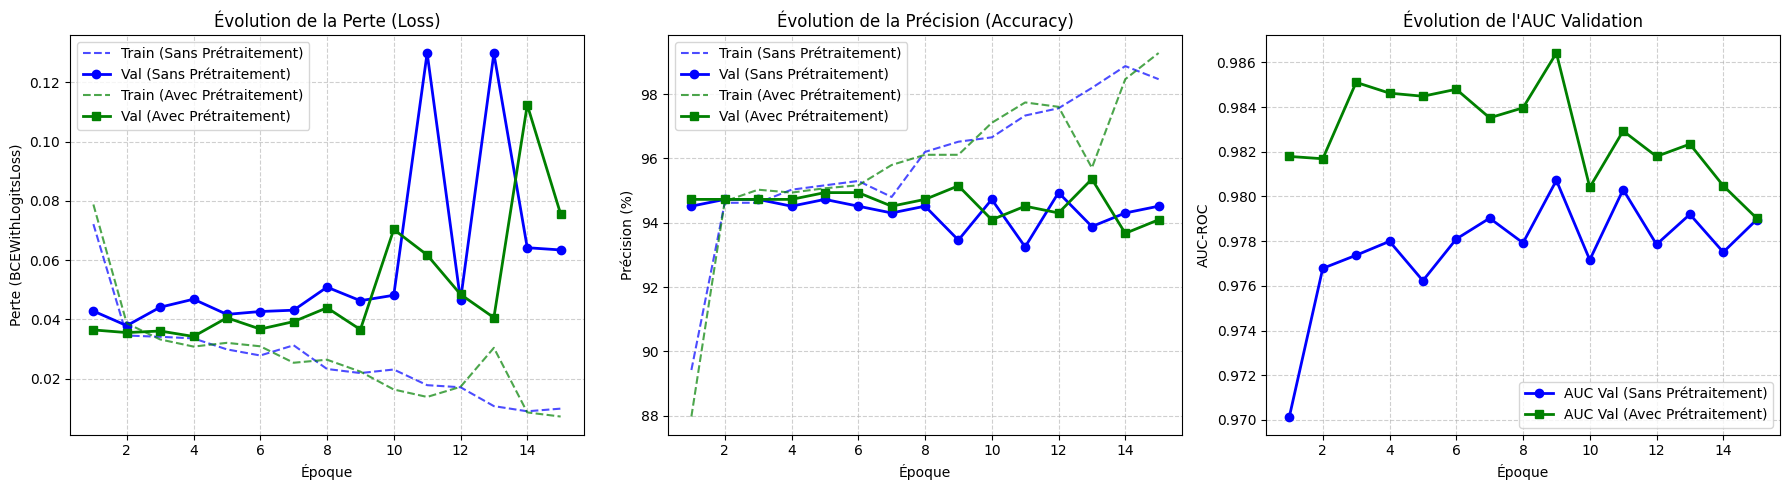

In [8]:
# Courbes d'Apprentissage
epochs = range(1, len(hist_rf_raw["train_loss"]) + 1)

plt.figure(figsize=(18, 5))

# Graphique Perte
plt.subplot(1, 3, 1)
plt.plot(
    epochs,
    hist_rf_raw["train_loss"],
    "b--",
    label="Train (Sans Prétraitement)",
    alpha=0.7,
)
plt.plot(
    epochs,
    hist_rf_raw["val_loss"],
    "b-o",
    label="Val (Sans Prétraitement)",
    linewidth=2,
)
plt.plot(
    epochs,
    hist_rf_prep["train_loss"],
    "g--",
    label="Train (Avec Prétraitement)",
    alpha=0.7,
)
plt.plot(
    epochs,
    hist_rf_prep["val_loss"],
    "g-s",
    label="Val (Avec Prétraitement)",
    linewidth=2,
)
plt.title("Évolution de la Perte (Loss)")
plt.xlabel("Époque")
plt.ylabel("Perte (BCEWithLogitsLoss)")
plt.legend()
plt.grid(True, linestyle="--", alpha=0.6)

# Graphique Précision
plt.subplot(1, 3, 2)
plt.plot(
    epochs,
    [acc * 100 for acc in hist_rf_raw["train_acc"]],
    "b--",
    label="Train (Sans Prétraitement)",
    alpha=0.7,
)
plt.plot(
    epochs,
    [acc * 100 for acc in hist_rf_raw["val_acc"]],
    "b-o",
    label="Val (Sans Prétraitement)",
    linewidth=2,
)
plt.plot(
    epochs,
    [acc * 100 for acc in hist_rf_prep["train_acc"]],
    "g--",
    label="Train (Avec Prétraitement)",
    alpha=0.7,
)
plt.plot(
    epochs,
    [acc * 100 for acc in hist_rf_prep["val_acc"]],
    "g-s",
    label="Val (Avec Prétraitement)",
    linewidth=2,
)
plt.title("Évolution de la Précision (Accuracy)")
plt.xlabel("Époque")
plt.ylabel("Précision (%)")
plt.legend()
plt.grid(True, linestyle="--", alpha=0.6)

# Graphique AUC-ROC
plt.subplot(1, 3, 3)
plt.plot(
    epochs,
    hist_rf_raw["val_auc"],
    "b-o",
    label="AUC Val (Sans Prétraitement)",
    linewidth=2,
)
plt.plot(
    epochs,
    hist_rf_prep["val_auc"],
    "g-s",
    label="AUC Val (Avec Prétraitement)",
    linewidth=2,
)
plt.title("Évolution de l'AUC Validation")
plt.xlabel("Époque")
plt.ylabel("AUC-ROC")
plt.legend()
plt.grid(True, linestyle="--", alpha=0.6)

plt.tight_layout()
plt.show()

In [9]:
# Évaluation
def evaluate_retfound(model, test_loader, name):
  model.eval()
  y_probs, y_true = [], []

  with torch.no_grad():
    for imgs, labels in test_loader:
      imgs = imgs.to(DEVICE)
      outputs = model(imgs).squeeze(1)
      probs = torch.sigmoid(outputs).cpu().numpy()

      y_probs.extend(probs)
      y_true.extend(labels.numpy())

  y_probs = np.array(y_probs)
  y_true = np.array(y_true)
  y_pred = (y_probs >= 0.5).astype(int)

  acc = accuracy_score(y_true, y_pred)
  sens = recall_score(y_true, y_pred)
  prec = precision_score(y_true, y_pred)
  f1 = f1_score(y_true, y_pred)
  auc_score = roc_auc_score(y_true, y_probs)

  tn, fp, fn, tp = confusion_matrix(y_true, y_pred).ravel()
  spec = tn / (tn + fp)

  print(f"\n--- {name} ---")
  print(f"Accuracy                 : {acc:.4f}")
  print(f"Sensibilité (Recall)     : {sens:.4f}")
  print(f"Spécificité              : {spec:.4f}")
  print(f"Précision                : {prec:.4f}")
  print(f"F1-score                 : {f1:.4f}")
  print(f"ROC-AUC                  : {auc_score:.4f}")

  return {
      "name": name,
      "y_prob": y_probs,
      "y_pred": y_pred,
      "y_true": y_true,
      "acc": acc,
      "sens": sens,
      "spec": spec,
      "prec": prec,
      "f1": f1,
      "auc": auc_score,
  }


res_rf_raw = evaluate_retfound(
    retfound_raw, test_loader_raw, "RETFound - Sans prétraitement"
)
res_rf_prep = evaluate_retfound(
    retfound_prep, test_loader_prep, "RETFound - Avec prétraitement"
)


--- RETFound - Sans prétraitement ---
Accuracy                 : 0.9473
Sensibilité (Recall)     : 0.9426
Spécificité              : 0.9726
Précision                : 0.9947
F1-score                 : 0.9680
ROC-AUC                  : 0.9813

--- RETFound - Avec prétraitement ---
Accuracy                 : 0.9536
Sensibilité (Recall)     : 0.9451
Spécificité              : 1.0000
Précision                : 1.0000
F1-score                 : 0.9718
ROC-AUC                  : 0.9797


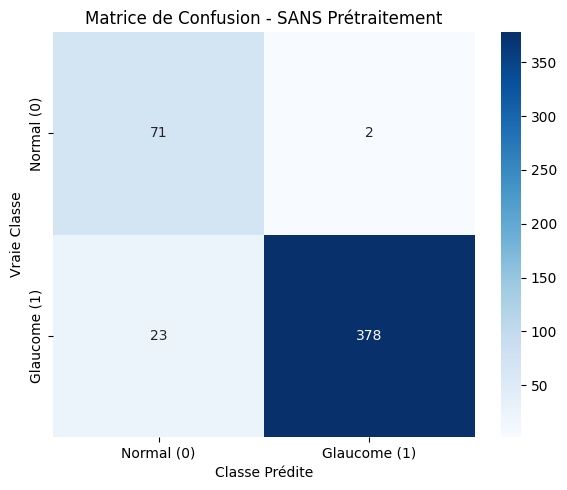

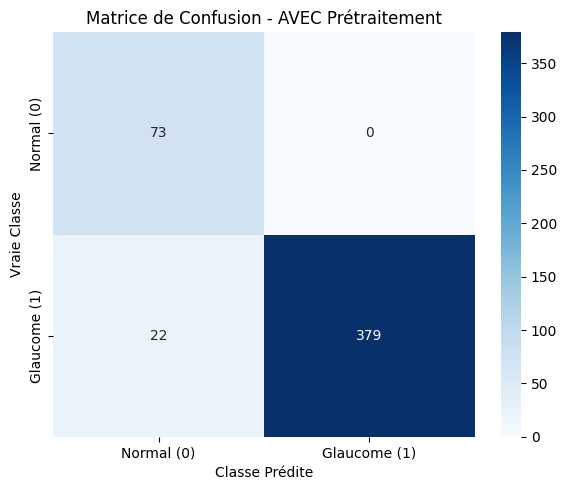

In [10]:
#Matrice de Confusion
def evaluate_and_plot_cm(
    model,
    test_loader,
    title="Modèle RETFound",
    class_names=["Normal (0)", "Glaucome (1)"],
):
  model.eval()
  all_targets = []
  all_probs = []

  with torch.no_grad():
    for imgs, labels in test_loader:
      imgs = imgs.to(DEVICE)
      outputs = model(imgs).view(-1)
      probs = torch.sigmoid(outputs)

      all_probs.extend(probs.cpu().numpy())
      all_targets.extend(labels.numpy())

  all_preds = (np.array(all_probs) >= 0.5).astype(int)
  all_targets = np.array(all_targets).astype(int)

  cm = confusion_matrix(all_targets, all_preds)

  plt.figure(figsize=(6, 5))
  sns.heatmap(
      cm,
      annot=True,
      fmt="d",
      cmap="Blues",
      xticklabels=class_names,
      yticklabels=class_names,
  )
  plt.title(f"Matrice de Confusion - {title}")
  plt.ylabel("Vraie Classe")
  plt.xlabel("Classe Prédite")
  plt.tight_layout()
  plt.show()

  return all_targets, all_probs


targets_raw, probs_raw = evaluate_and_plot_cm(
    retfound_raw, test_loader_raw, title="SANS Prétraitement"
)

targets_prep, probs_prep = evaluate_and_plot_cm(
    retfound_prep, test_loader_prep, title="AVEC Prétraitement"
)

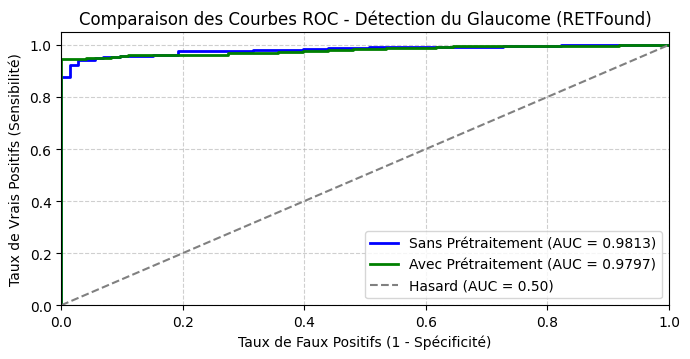


=================== TABLEAU COMPARATIF ===================
                     Pipeline  Accuracy  Sensibilité  Spécificité  Précision  F1-Score  ROC-AUC
RETFound - Sans prétraitement  0.947257     0.942643     0.972603   0.994737  0.967990 0.981314
RETFound - Avec prétraitement  0.953586     0.945137     1.000000   1.000000  0.971795 0.979674


In [11]:
# Courbes ROC & Bilan
plt.figure(figsize=(7, 3.7))

# Courbe ROC Sans Prétraitement
fpr_raw, tpr_raw, _ = roc_curve(targets_raw, probs_raw)
auc_raw = auc(fpr_raw, tpr_raw)
plt.plot(
    fpr_raw,
    tpr_raw,
    color="blue",
    lw=2,
    label=f"Sans Prétraitement (AUC = {auc_raw:.4f})",
)

# Courbe ROC Avec Prétraitement
fpr_prep, tpr_prep, _ = roc_curve(targets_prep, probs_prep)
auc_prep = auc(fpr_prep, tpr_prep)
plt.plot(
    fpr_prep,
    tpr_prep,
    color="green",
    lw=2,
    label=f"Avec Prétraitement (AUC = {auc_prep:.4f})",
)

plt.plot(
    [0, 1],
    [0, 1],
    color="gray",
    lw=1.5,
    linestyle="--",
    label="Hasard (AUC = 0.50)",
)

plt.xlim([0.0, 1.0])
plt.ylim([0.0, 1.05])
plt.xlabel("Taux de Faux Positifs (1 - Spécificité)")
plt.ylabel("Taux de Vrais Positifs (Sensibilité)")
plt.title("Comparaison des Courbes ROC - Détection du Glaucome (RETFound)")
plt.legend(loc="lower right")
plt.grid(True, linestyle="--", alpha=0.6)
plt.tight_layout()
plt.show()

# Tableau récapitulatif
results_df = pd.DataFrame([res_rf_raw, res_rf_prep])[
    ["name", "acc", "sens", "spec", "prec", "f1", "auc"]
]
results_df.columns = [
    "Pipeline",
    "Accuracy",
    "Sensibilité",
    "Spécificité",
    "Précision",
    "F1-Score",
    "ROC-AUC",
]

print("\n=================== TABLEAU COMPARATIF ===================")
print(results_df.to_string(index=False))

In [12]:
# Test sur Image Externe
from google.colab import files

print(
    "Veuillez uploader une image de fond d'œil (formats acceptés : PNG, JPG,"
    " JPEG)"
)
uploaded = files.upload()

if len(uploaded) > 0:
  image_name = list(uploaded.keys())[0]

  raw_img = load_raw(image_name)
  prep_img = load_preprocessed(image_name)

  fig, axes = plt.subplots(1, 2, figsize=(10, 2.7))
  axes[0].imshow(raw_img.astype(np.uint8))
  axes[0].set_title("Image Brute (Raw)")
  axes[0].axis("off")

  axes[1].imshow(prep_img.astype(np.uint8))
  axes[1].set_title("Image Prétraitée (CLAHE + Crop)")
  axes[1].axis("off")
  plt.tight_layout()
  plt.show()

  def predict_single_retfound(model, img_array, model_name):
    model.eval()
    tensor_img = (
        transform_pipeline(img_array.astype(np.uint8)).unsqueeze(0).to(DEVICE)
    )

    with torch.no_grad():
      logit = model(tensor_img).squeeze(1)
      prob = torch.sigmoid(logit).item()

    pred_label = "Glaucome" if prob >= 0.5 else "Sain"

    print(f"\n--- {model_name} ---")
    print(f"Probabilité de glaucome : {prob:.4f}")
    print(f"Diagnostic prédit       : {pred_label}")
    return prob, pred_label

  print("\n================ RÉSULTATS DES PRÉDICTIONS ================")
  prob_raw, label_raw = predict_single_retfound(
      retfound_raw, raw_img, "RETFound - Sans Prétraitement"
  )
  prob_prep, label_prep = predict_single_retfound(
      retfound_prep, prep_img, "RETFound - Avec Prétraitement"
  )

else:
  print("Aucune image n'a été uploadée.")

Veuillez uploader une image de fond d'œil (formats acceptés : PNG, JPG, JPEG)


Aucune image n'a été uploadée.
